# Households with Waste Collection Service, Nonthaburi Province

**Data:** `data/raw/store.csv` — number of households receiving waste collection/disposal service (`คร.ที่กำจัดขยะ`) per local government (อปท.) per year (Buddhist Era 2563–2567 = 2020–2024)

**Steps in this notebook**
1. Load and explore the data
2. Handle missing values (~30% of rows) with tiered median imputation
3. Save as `data/clean/clean_store.csv`
4. Visualize: yearly trend, share by district, local governments serving the most households, and how many values were imputed

# ครัวเรือนที่มีการจัดเก็บขยะมูลฝอย จังหวัดนนทบุรี

**ข้อมูล:** `data/raw/store.csv` — จำนวนครัวเรือนที่ได้รับบริการจัดเก็บ/กำจัดขยะ (`คร.ที่กำจัดขยะ`) ราย อปท. รายปี (พ.ศ. 2563–2567)

**ขั้นตอนใน notebook นี้**
1. โหลดและสำรวจข้อมูล
2. จัดการค่าสูญหาย (~30% ของแถว) ด้วยการเติมค่ามัธยฐานแบบลำดับชั้น
3. บันทึกเป็น `data/clean/clean_store.csv`
4. แสดงผลด้วยกราฟ: แนวโน้มรายปี, สัดส่วนรายอำเภอ, อปท. ที่ให้บริการมากที่สุด และปริมาณค่าที่ถูกเติม

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the raw data** from `../data/raw/store.csv` and show the whole table

**โหลดข้อมูลดิบ** จาก `../data/raw/store.csv` และแสดงตารางทั้งหมด

In [2]:
df = pd.read_csv('../data/raw/store.csv')
df

,ปี,จังหวัด,อำเภอ,อปท,คร.ที่กำจัดขยะ
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,"189,356"
1,2563,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,"22,106"
2,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,"7,332"
3,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางบัวทอง,"25,269"
4,2563,นนทบุรี,บางใหญ่,เทศบาลเมืองบางแม่นาง,"23,655"
...,...,...,...,...,...
147,2567,นนทบุรี,ไทรน้อย,อบต.ราษฎร์นิยม,"1,157"
148,2567,นนทบุรี,บางบัวทอง,อบต.ละหาร,"13,162"
149,2567,นนทบุรี,บางบัวทอง,อบต.ลำโพ,"8,611"
150,2567,นนทบุรี,ไทรน้อย,อบต.หนองเพรางาย,NaN


**Count missing values** in each column with `isnull().sum()` — 0 in every column means there are no gaps

The `คร.ที่กำจัดขยะ` (households served) column has many missing values → handled in the next steps

**นับค่าสูญหาย (Missing values)** ในแต่ละคอลัมน์ด้วย `isnull().sum()` — ถ้าเป็น 0 ทุกคอลัมน์แปลว่าไม่มีช่องว่าง

พบว่าคอลัมน์ `คร.ที่กำจัดขยะ` มีค่าว่างจำนวนมาก → จัดการในขั้นถัดไป

In [3]:
df.isnull().sum()

ปี                 0
จังหวัด            0
อำเภอ              0
อปท                0
คร.ที่กำจัดขยะ    46
dtype: int64

## Missing Value Treatment

**Problems found:**
1. `คร.ที่กำจัดขยะ` is stored as a string (with `,` separators) and must be converted to numeric first
2. There are 46 missing rows (~30%)

**Imputation strategy:**
Because this is panel data (the same local governments measured over several years), the following order is used
1. Fill with the **median of the same local government** across years (local governments differ greatly in size)
2. If still missing → fill with the **median of the same district** (geographically close)
3. If still missing → fill with the **overall median** (fallback)

## การจัดการค่าสูญหาย (Missing Value Treatment)

**ปัญหาที่พบ:**
1. `คร.ที่กำจัดขยะ` เก็บเป็น string (มีเครื่องหมาย `,`) ต้องแปลงเป็น numeric ก่อน
2. มีค่าสูญหาย 46 แถว (~30%)

**กลยุทธ์การเติมค่า (Imputation Strategy):**
เนื่องจากข้อมูลเป็น Panel Data (อปท. เดิมวัดซ้ำหลายปี) จึงใช้ลำดับดังนี้
1. เติมด้วย **ค่ามัธยฐานของ อปท. เดียวกัน** ข้ามปี (อปท. ขนาดต่างกันมาก)
2. หากยังขาด → เติมด้วย **ค่ามัธยฐานของ อำเภอ เดียวกัน** (ใกล้เคียงตามภูมิศาสตร์)
3. หากยังขาด → เติมด้วย **ค่ามัธยฐานรวม** (Fallback)

**Step 1 – Analyze the pattern of missing values** before choosing how to fill them

- Count gaps by **year** and **district** to see whether they are random or concentrated somewhere
- Find local governments with **no data in any year** — these cannot be filled from their own values and need district-level values instead

**Step 1 – วิเคราะห์รูปแบบของค่าสูญหาย** ก่อนตัดสินใจวิธีเติม

- นับค่าว่างแยกตาม **ปี** และ **อำเภอ** เพื่อดูว่าหายแบบสุ่มหรือกระจุกที่ใดที่หนึ่ง
- หา อปท. ที่ **ไม่มีข้อมูลเลยทุกปี** — กลุ่มนี้เติมด้วยค่าของตัวเองไม่ได้ ต้องใช้ค่าระดับอำเภอแทน

In [4]:
# ── Step 1: analyze missing values ──────────────────────────────────────
# ── Step 1: วิเคราะห์ค่าสูญหาย ──────────────────────────────────────────
print("=== ค่าสูญหายแยกตามปี ===")
print(df.groupby('ปี')['คร.ที่กำจัดขยะ'].apply(lambda x: x.isnull().sum()).rename('จำนวนที่หาย'))
print()
print("=== ค่าสูญหายแยกตามอำเภอ ===")
print(df.groupby('อำเภอ')['คร.ที่กำจัดขยะ'].apply(lambda x: x.isnull().sum()).rename('จำนวนที่หาย'))
print()
print("=== อปท. ที่มีค่าสูญหายทุกปี (ไม่มีข้อมูลเลย) ===")
all_null_apt = (df.groupby('อปท')['คร.ที่กำจัดขยะ']
                  .apply(lambda x: x.isnull().all()))
print(all_null_apt[all_null_apt].index.tolist())

=== ค่าสูญหายแยกตามปี ===
ปี
2563     0
2564     0
2565     0
2566    25
2567    21
Name: จำนวนที่หาย, dtype: int64

=== ค่าสูญหายแยกตามอำเภอ ===
อำเภอ
บางกรวย          5
บางบัวทอง        9
บางใหญ่          7
ปากเกร็ด         9
เมืองนนทบุรี     4
ไทรน้อย         12
Name: จำนวนที่หาย, dtype: int64

=== อปท. ที่มีค่าสูญหายทุกปี (ไม่มีข้อมูลเลย) ===
['อบต.บางขุนกอง', 'อบต.หนองเพรางาย', 'เทศบาลนครนนทบุรี', 'เทศบาลนครบางบัวทอง', 'เทศบาลเมืองพิมลราช']


**Step 2 – Convert data types and fill missing values (3 tiers)**

- **2a** Remove `,` and convert to numbers (`pd.to_numeric(errors='coerce')` — values that cannot be converted become NaN)
- **2b** Fill with the median of the **same local government** (across years) → most accurate because it is the same organization
- **2c** Fill what is still empty with the median of the **same district**
- **2d** Fill anything still empty with the **province-wide median** (safety net)
- Finally round to whole numbers, because household counts have no decimals

**Step 2 – แปลงชนิดข้อมูลและเติมค่าสูญหาย (3 ชั้น)**

- **2a** ลบ `,` แล้วแปลงเป็นตัวเลข (`pd.to_numeric(errors='coerce')` — ค่าที่แปลงไม่ได้จะกลายเป็น NaN)
- **2b** เติมด้วย median ของ **อปท. เดียวกัน** (ข้ามปี) → แม่นยำที่สุดเพราะเป็นหน่วยงานเดิม
- **2c** ที่ยังว่าง เติมด้วย median ของ **อำเภอเดียวกัน**
- **2d** ที่ยังว่างอีก เติมด้วย **median รวมทั้งจังหวัด** (กันพลาด)
- สุดท้ายปัดเป็นจำนวนเต็ม เพราะจำนวนครัวเรือนไม่มีทศนิยม

In [5]:
# ── Step 2: convert data types and fill missing values ──────────────────
# ── Step 2: แปลงชนิดข้อมูลและเติมค่าสูญหาย ───────────────────────────────
df_clean = df.copy()

# 2a. convert string → numeric (remove the , separators)
# 2a. แปลง string → numeric (ลบเครื่องหมาย ,)
df_clean['คร.ที่กำจัดขยะ'] = (
    df_clean['คร.ที่กำจัดขยะ']
    .astype(str)
    .str.replace(',', '', regex=False)
    .replace('nan', np.nan)
    .pipe(pd.to_numeric, errors='coerce')
)

before = df_clean['คร.ที่กำจัดขยะ'].isnull().sum()
print(f"NaN ก่อนเติม: {before}")

# 2b. fill with the median of the same local government (method 1)
# 2b. เติมด้วยค่ามัธยฐานของ อปท. เดียวกัน (วิธีที่ 1)
df_clean['คร.ที่กำจัดขยะ'] = (
    df_clean.groupby('อปท')['คร.ที่กำจัดขยะ']
    .transform(lambda x: x.fillna(x.median()))
)

after_step1 = df_clean['คร.ที่กำจัดขยะ'].isnull().sum()
print(f"NaN หลังเติมด้วย median ของ อปท.: {after_step1}")

# 2c. fill with the median of the same district (method 2 — fallback)
# 2c. เติมด้วยค่ามัธยฐานของ อำเภอ เดียวกัน (วิธีที่ 2 — fallback)
df_clean['คร.ที่กำจัดขยะ'] = (
    df_clean.groupby('อำเภอ')['คร.ที่กำจัดขยะ']
    .transform(lambda x: x.fillna(x.median()))
)

after_step2 = df_clean['คร.ที่กำจัดขยะ'].isnull().sum()
print(f"NaN หลังเติมด้วย median ของ อำเภอ: {after_step2}")

# 2d. fill with the overall median (method 3 — last resort)
# 2d. เติมด้วย median รวม (วิธีที่ 3 — last resort)
global_median = df_clean['คร.ที่กำจัดขยะ'].median()
df_clean['คร.ที่กำจัดขยะ'] = df_clean['คร.ที่กำจัดขยะ'].fillna(global_median)

after_step3 = df_clean['คร.ที่กำจัดขยะ'].isnull().sum()
print(f"NaN หลังเติมด้วย median รวม (fallback): {after_step3}")

# convert to int (households have no decimals)
# แปลงเป็น int (ครัวเรือนไม่มีทศนิยม)
df_clean['คร.ที่กำจัดขยะ'] = df_clean['คร.ที่กำจัดขยะ'].round().astype(int)

print(f"\nสรุป: เติมค่าทั้งหมด {before} แถว เสร็จสมบูรณ์")
df_clean

NaN ก่อนเติม: 46
NaN หลังเติมด้วย median ของ อปท.: 10
NaN หลังเติมด้วย median ของ อำเภอ: 0
NaN หลังเติมด้วย median รวม (fallback): 0

สรุป: เติมค่าทั้งหมด 46 แถว เสร็จสมบูรณ์


,ปี,จังหวัด,อำเภอ,อปท,คร.ที่กำจัดขยะ
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,189356
1,2563,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,22106
2,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,7332
3,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางบัวทอง,25269
4,2563,นนทบุรี,บางใหญ่,เทศบาลเมืองบางแม่นาง,23655
...,...,...,...,...,...
147,2567,นนทบุรี,ไทรน้อย,อบต.ราษฎร์นิยม,1157
148,2567,นนทบุรี,บางบัวทอง,อบต.ละหาร,13162
149,2567,นนทบุรี,บางบัวทอง,อบต.ลำโพ,8611
150,2567,นนทบุรี,ไทรน้อย,อบต.หนองเพรางาย,1622


**Step 3 – Check the result**: no missing values remain, and look at basic statistics (min, mean, quartiles, max) of the household counts

**Step 3 – ตรวจสอบผลลัพธ์** ว่าไม่เหลือค่าว่าง และดูสถิติเบื้องต้น (ค่าต่ำสุด ค่าเฉลี่ย ควอไทล์ ค่าสูงสุด) ของจำนวนครัวเรือน

In [6]:
# ── Step 3: check and save ─────────────────────────────────────────────
# ── Step 3: ตรวจสอบและบันทึก ─────────────────────────────────────────────
print("=== ตรวจสอบหลังทำความสะอาด ===")
df_clean.info()
print()
print(f"ค่าสูญหายคงเหลือ: {df_clean.isnull().sum().sum()}")
print()
print("=== สถิติเบื้องต้นของ คร.ที่กำจัดขยะ ===")
print(df_clean['คร.ที่กำจัดขยะ'].describe().apply(lambda x: f"{x:,.0f}"))

=== ตรวจสอบหลังทำความสะอาด ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ปี              152 non-null    int64 
 1   จังหวัด         152 non-null    object
 2   อำเภอ           152 non-null    object
 3   อปท             152 non-null    object
 4   คร.ที่กำจัดขยะ  152 non-null    int64 
dtypes: int64(2), object(3)
memory usage: 6.1+ KB

ค่าสูญหายคงเหลือ: 0

=== สถิติเบื้องต้นของ คร.ที่กำจัดขยะ ===
count        152
mean      11,740
std       20,300
min            0
25%        1,891
50%        5,484
75%       12,672
max      189,356
Name: คร.ที่กำจัดขยะ, dtype: object


**Convert the province / district / local government columns to `category` and save the file** `data/clean/clean_store.csv`

**แปลงคอลัมน์ จังหวัด / อำเภอ / อปท เป็น `category` แล้วบันทึกไฟล์** `data/clean/clean_store.csv`

In [7]:
for col in df_clean.columns[1:4]:
    df_clean[col] = df_clean[col].astype('category')
df_clean.info()
df_clean.to_csv('../data/clean/clean_store.csv', index=False)
print("\nบันทึก clean data สำเร็จ: ../data/clean/clean_store.csv")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   ปี              152 non-null    int64   
 1   จังหวัด         152 non-null    category
 2   อำเภอ           152 non-null    category
 3   อปท             152 non-null    category
 4   คร.ที่กำจัดขยะ  152 non-null    int64   
dtypes: category(3), int64(2)
memory usage: 4.7 KB

บันทึก clean data สำเร็จ: ../data/clean/clean_store.csv


---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [8]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma

In [9]:
# Copy of the data for charting: convert category → text (does not affect the original table)
# สำเนาข้อมูลสำหรับทำกราฟ: แปลง category → ข้อความ (ไม่กระทบตารางต้นฉบับ)
viz = df_clean.copy()
for c in viz.select_dtypes('category').columns:
    viz[c] = viz[c].astype(str)
viz = viz.loc[:, ~viz.columns.str.startswith(('median', 'Unnamed'))]   # drop helper columns — ตัดคอลัมน์ช่วยคำนวณ
print(viz.shape)
viz.head()

(152, 5)

,ปี,จังหวัด,อำเภอ,อปท,คร.ที่กำจัดขยะ
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,189356
1,2563,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,22106
2,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,7332
3,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางบัวทอง,25269
4,2563,นนทบุรี,บางใหญ่,เทศบาลเมืองบางแม่นาง,23655


### 2.1 Line chart: total households receiving waste collection per year
**What it does:** sums the households of every local government in each year

**How to read it:** an upward trend means collection covers more households (possibly from population growth or local governments expanding their service areas)

### 2.1 กราฟเส้น: จำนวนครัวเรือนที่ได้รับบริการจัดเก็บขยะรวมรายปี
**ทำอะไร:** รวมจำนวนครัวเรือนของทุก อปท. ในแต่ละปี

**วิธีอ่าน:** แนวโน้มขาขึ้นแปลว่าบริการเก็บขยะครอบคลุมครัวเรือนมากขึ้น (อาจมาจากประชากรเพิ่ม หรือ อปท. ขยายพื้นที่บริการ)

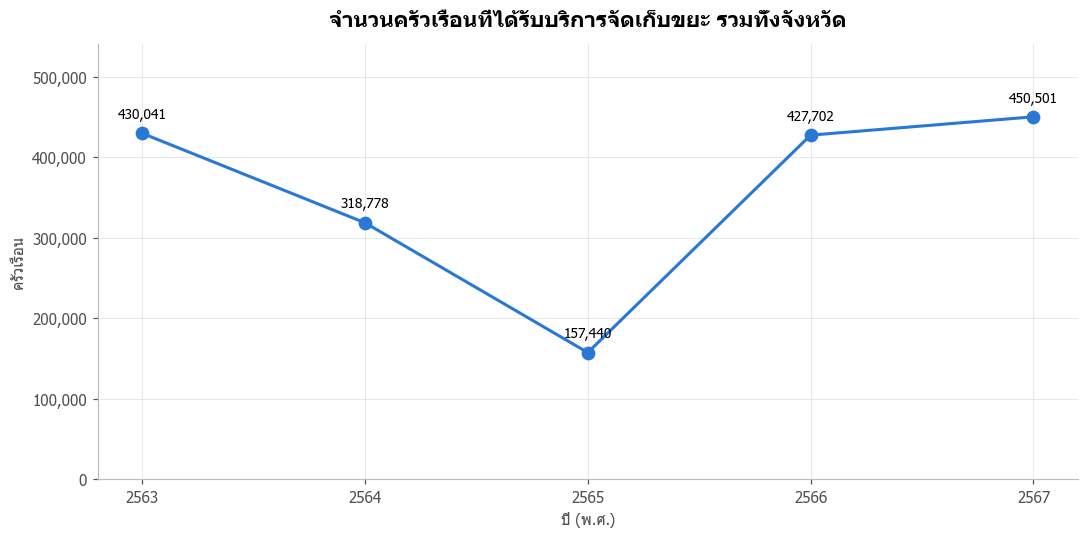

In [10]:
col = 'คร.ที่กำจัดขยะ'
yearly = viz.groupby('ปี')[col].sum()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly.index, yearly.values, marker='o', markersize=8, linewidth=2, color=PALETTE[0])
for x, y in zip(yearly.index, yearly.values):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.set_xticks(yearly.index)
ax.set_ylim(0, yearly.max() * 1.2)
ax.yaxis.set_major_formatter(fmt_k)
ax.set_title('จำนวนครัวเรือนที่ได้รับบริการจัดเก็บขยะ รวมทั้งจังหวัด')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ครัวเรือน')
plt.tight_layout(); plt.show()

### 2.2 Stacked bar chart: households per year by district
**How to read it:** the full bar height = the province total, each color is one district's share — shows which districts are the main base of the service and whether the shares change over the years

### 2.2 กราฟแท่งซ้อน: จำนวนครัวเรือนรายปี แยกตามอำเภอ
**วิธีอ่าน:** ความสูงทั้งแท่ง = ยอดรวมทั้งจังหวัด แต่ละสีคือส่วนของแต่ละอำเภอ — ดูว่าอำเภอไหนเป็นฐานหลักของการให้บริการ และสัดส่วนเปลี่ยนไปตามปีหรือไม่

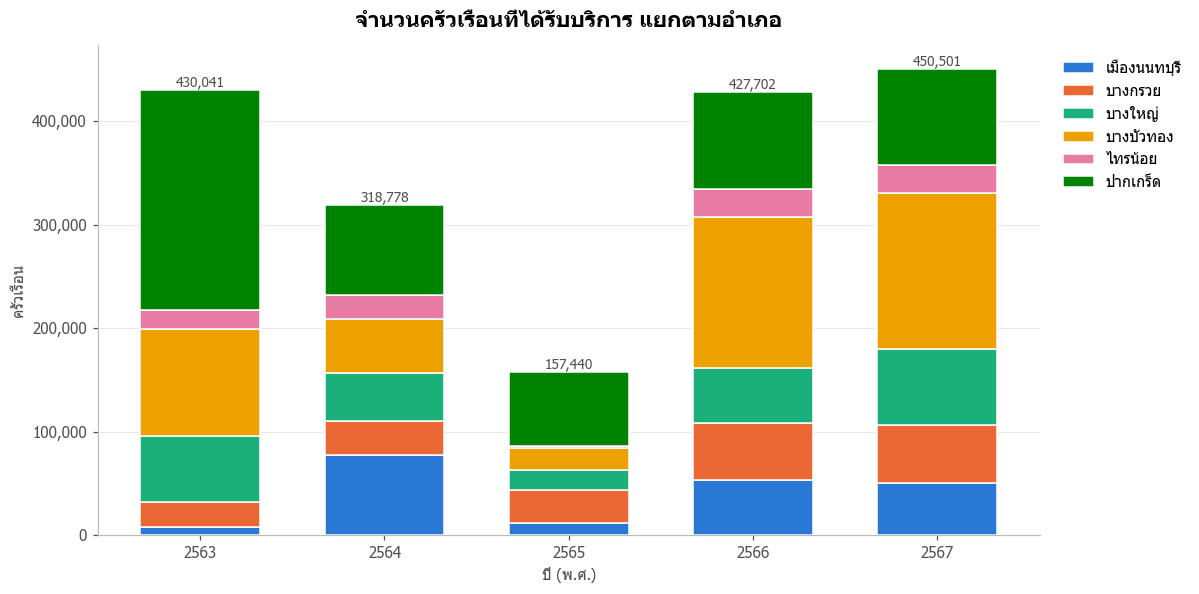

อำเภอ,เมืองนนทบุรี,บางกรวย,บางใหญ่,บางบัวทอง,ไทรน้อย,ปากเกร็ด
ปี,,,,,,
2563,8052,24369,63184,103461,18312,212663
2564,77216,33205,45861,52549,23202,86745
2565,12000,31625,19205,21590,1872,71148
2566,53418,55042,52791,145971,27304,93176
2567,50739,55835,73084,150335,27150,93358


In [11]:
col = 'คร.ที่กำจัดขยะ'
pivot = (viz.pivot_table(index='ปี', columns='อำเภอ', values=col, aggfunc='sum')
            .reindex(columns=[d for d in DIST_ORDER if d in set(viz['อำเภอ'])]))
fig, ax = plt.subplots(figsize=(11, 5.5))
totals = stacked_bar(ax, pivot)
for i, t in enumerate(totals):
    ax.text(i, t, f'{t:,.0f}', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.yaxis.set_major_formatter(fmt_k)
ax.set_title('จำนวนครัวเรือนที่ได้รับบริการ แยกตามอำเภอ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ครัวเรือน')
plt.tight_layout(); plt.show()
pivot

### 2.3 Pie chart: share of households served by district (latest year)
**What it does:** uses only the latest year (`viz['ปี'].max()`) to show the current picture

**How to read it:** a big slice = a district with many households served; the actual numbers and % are in the legend on the right

### 2.3 แผนภูมิวงกลม: สัดส่วนครัวเรือนที่ได้รับบริการ แยกตามอำเภอ (ปีล่าสุด)
**ทำอะไร:** ใช้เฉพาะข้อมูลปีล่าสุด (`viz['ปี'].max()`) เพื่อให้เห็นภาพปัจจุบัน

**วิธีอ่าน:** ชิ้นที่ใหญ่ = อำเภอที่มีครัวเรือนรับบริการมาก ตัวเลขจริงและ % อยู่ใน legend ด้านขวา

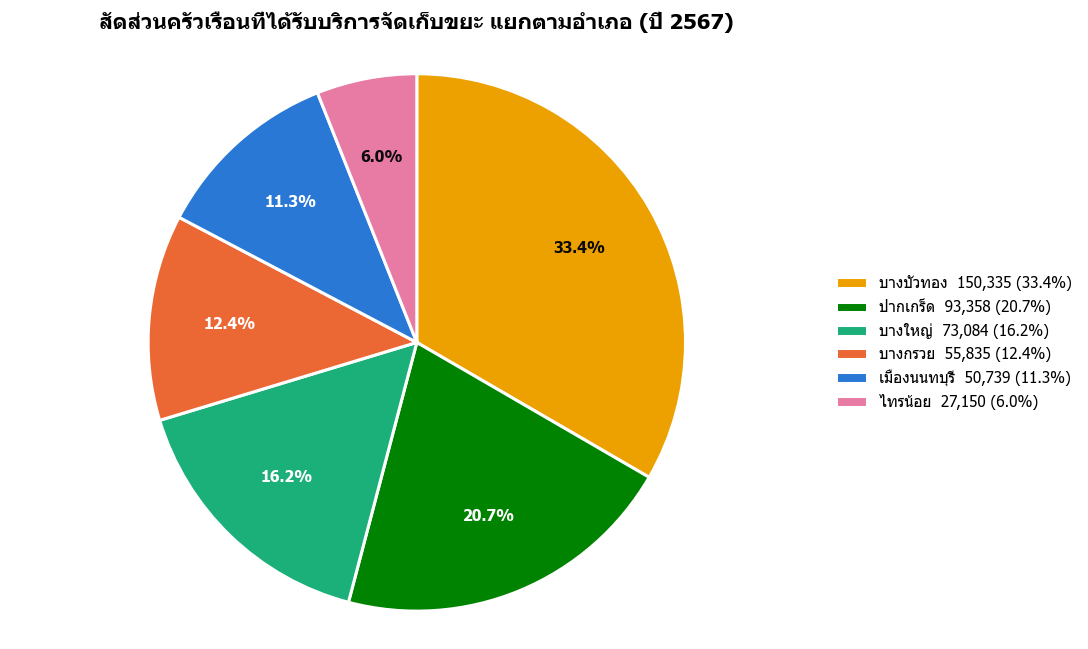

In [12]:
col = 'คร.ที่กำจัดขยะ'
latest = viz['ปี'].max()
share = (viz[viz['ปี'] == latest].groupby('อำเภอ')[col].sum().sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(10, 6))
pie_chart(ax, share.values, share.index, colors=[DIST_COLOR.get(d, GRAY) for d in share.index],
          title=f'สัดส่วนครัวเรือนที่ได้รับบริการจัดเก็บขยะ แยกตามอำเภอ (ปี {latest})')
plt.tight_layout(); plt.show()

### 2.4 Horizontal bar chart: top 10 local governments serving the most households (latest year)
**How to read it:** shows concentration — if the #1 local government is much bigger than the rest, the province's collection workload depends mainly on it

### 2.4 กราฟแท่งแนวนอน: 10 อปท. ที่ให้บริการครัวเรือนมากที่สุด (ปีล่าสุด)
**วิธีอ่าน:** แสดงการกระจุกตัว — ถ้า อปท. อันดับ 1 ใหญ่กว่าที่เหลือมาก แปลว่าภาระงานเก็บขยะของจังหวัดพึ่งพา อปท. นั้นเป็นหลัก

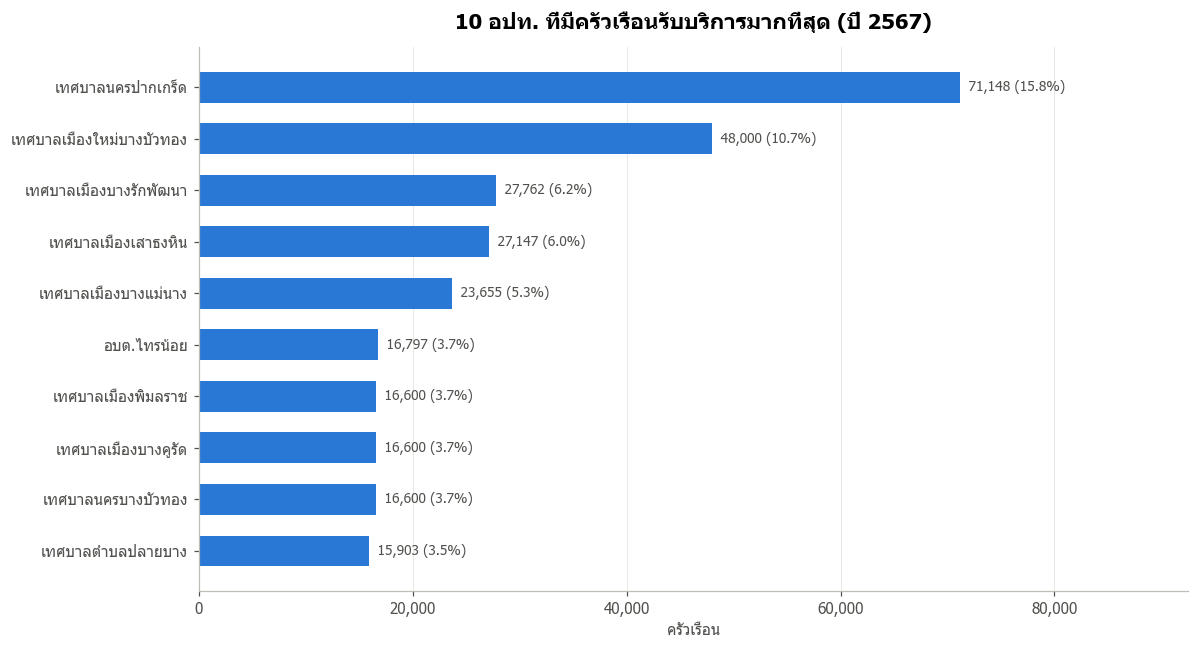

In [13]:
col = 'คร.ที่กำจัดขยะ'
latest = viz['ปี'].max()
by_apt = viz[viz['ปี'] == latest].groupby('อปท')[col].sum()
top = by_apt.nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top.index, top.values, color=PALETTE[0], height=0.6)
for b, v in zip(bars, top.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f'  {v:,.0f} ({v / by_apt.sum() * 100:.1f}%)',
            va='center', fontsize=9, color=TEXT)
ax.set_xlim(0, top.max() * 1.3)
ax.xaxis.set_major_formatter(fmt_k); ax.grid(axis='y', visible=False)
ax.set_title(f'10 อปท. ที่มีครัวเรือนรับบริการมากที่สุด (ปี {latest})'); ax.set_xlabel('ครัวเรือน')
plt.tight_layout(); plt.show()

### 2.5 Distribution of local government size (histogram, log scale)
**What it does:** shows how many households most local governments serve. The x-axis uses a **log** scale because there are both small local governments (hundreds) and very large ones (hundreds of thousands)

**How to read it:** the peak is the most common size; points far to the right are large local governments (city municipalities)

### 2.5 การกระจายของขนาด อปท. (Histogram, สเกล log)
**ทำอะไร:** ดูว่า อปท. ส่วนใหญ่ให้บริการกี่ครัวเรือน ใช้แกน x แบบ **log** เพราะมีทั้ง อปท. เล็ก (หลักร้อย) และใหญ่มาก (หลักแสน)

**วิธีอ่าน:** ยอดเขาของกราฟคือขนาดที่พบบ่อยที่สุด จุดที่อยู่ห่างไปทางขวาคือ อปท. ขนาดใหญ่ (เทศบาลนคร)

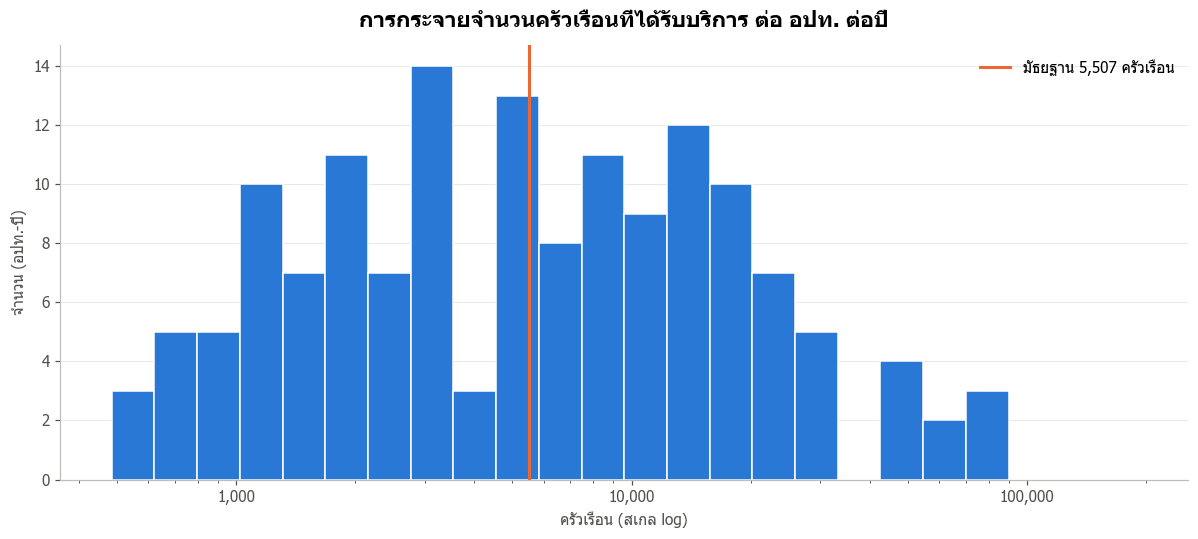

ไม่รวมแถวที่มีค่าเป็น 0 จำนวน 2 แถว


In [14]:
col = 'คร.ที่กำจัดขยะ'
vals = viz.loc[viz[col] > 0, col]
fig, ax = plt.subplots(figsize=(11, 5))
bins = np.logspace(np.log10(vals.min()), np.log10(vals.max()), 25)
ax.hist(vals, bins=bins, color=PALETTE[0], edgecolor='white', linewidth=1)
ax.axvline(vals.median(), color=PALETTE[1], linewidth=2, label=f'มัธยฐาน {vals.median():,.0f} ครัวเรือน')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(fmt_k)
ax.grid(axis='x', visible=False); ax.legend()
ax.set_title('การกระจายจำนวนครัวเรือนที่ได้รับบริการ ต่อ อปท. ต่อปี')
ax.set_xlabel('ครัวเรือน (สเกล log)'); ax.set_ylabel('จำนวน (อปท.-ปี)')
plt.tight_layout(); plt.show()
print(f'ไม่รวมแถวที่มีค่าเป็น 0 จำนวน {(viz[col] == 0).sum()} แถว')

### 2.6 Data quality: number of imputed values per year
**What it does:** counts from the raw data (`df`) how many rows per year were missing and filled with the median, compared with rows that had real values

**Why it matters:** in years with a high share of imputed values the analysis is more "estimate" than "real data" — be careful when interpreting the trend for those years

### 2.6 คุณภาพข้อมูล: จำนวนค่าที่ถูกเติม (Imputed) ในแต่ละปี
**ทำอะไร:** นับจากข้อมูลดิบ (`df`) ว่าแต่ละปีมีกี่แถวที่ค่าว่างและถูกเติมด้วยค่ามัธยฐาน เทียบกับแถวที่มีค่าจริง

**ทำไมสำคัญ:** ปีที่มีสัดส่วนค่าเติมสูง ผลวิเคราะห์จะ "ประมาณการ" มากกว่า "ข้อมูลจริง" ควรระวังเมื่อตีความแนวโน้มของปีนั้น

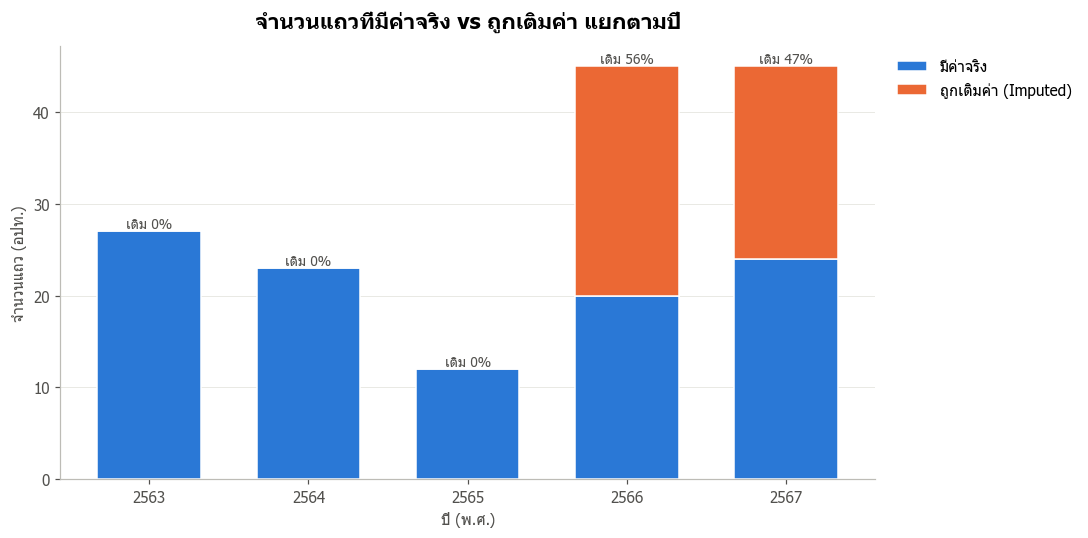

,มีค่าจริง,ถูกเติมค่า (Imputed)
ปี,,
2563,27,0
2564,23,0
2565,12,0
2566,20,25
2567,24,21


In [15]:
col = 'คร.ที่กำจัดขยะ'
quality = pd.DataFrame({
    'มีค่าจริง': df[col].notnull().groupby(df['ปี']).sum(),
    'ถูกเติมค่า (Imputed)': df[col].isnull().groupby(df['ปี']).sum(),
})
fig, ax = plt.subplots(figsize=(10, 5))
totals = stacked_bar(ax, quality, colors=[PALETTE[0], PALETTE[1]])
for i, (t, miss) in enumerate(zip(totals, quality.iloc[:, 1])):
    ax.text(i, t, f'เติม {miss / t * 100:.0f}%', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.set_title('จำนวนแถวที่มีค่าจริง vs ถูกเติมค่า แยกตามปี')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('จำนวนแถว (อปท.)')
plt.tight_layout(); plt.show()
quality

---
## Key Findings

1. **The totals rise and fall with the number of reporting local governments, not with actual service** — 2565 (2022) has only 12 local governments in the file (2566–2567 have 45), so the total drops to ~157,000 households before returning to ~450,000 in 2567 (2024). The line chart should not be read as "service fell and then rose"
2. **In 2567 (2024) Bang Bua Thong district has the most households served (~33%)**, followed by Pak Kret (~21%)
3. **Pak Kret City Municipality serves the most households** (~71,000 households, or ~16% of the province in 2567)
4. **Imputed values are concentrated in 2566–2567** (25 and 21 rows), so the figures for these two years are more "estimated" than other years

## สรุปข้อค้นพบ

1. **ยอดรวมขึ้นลงตามจำนวน อปท. ที่รายงาน ไม่ใช่บริการจริง** — ปี 2565 มีเพียง 12 อปท. ในไฟล์ (ปี 2566–2567 มี 45 แห่ง) ยอดจึงตกเหลือ ~157,000 ครัวเรือน ก่อนกลับมา ~450,000 ในปี 2567 จึงไม่ควรอ่านกราฟเส้นว่า "บริการลดลงแล้วเพิ่มขึ้น"
2. **ปี 2567 อำเภอบางบัวทองมีครัวเรือนรับบริการมากที่สุด (~33%)** ตามด้วยปากเกร็ด (~21%)
3. **เทศบาลนครปากเกร็ดเป็น อปท. ที่ให้บริการมากที่สุด** (~71,000 ครัวเรือน หรือ ~16% ของจังหวัดในปี 2567)
4. **ค่าที่ถูกเติม (imputed) กระจุกอยู่ในปี 2566–2567** (25 และ 21 แถว) ตัวเลขสองปีนี้จึงเป็น "ค่าประมาณ" มากกว่าปีอื่น